In [1]:

%pip install -q "segmentation-models-pytorch==0.5.0" tifffile


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 5.4 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import tifffile
import segmentation_models_pytorch as smp

print("=" * 55)
print("WEEK 3 — MULTISPECTRAL WATER SEGMENTATION")
print("=" * 55)

print("PyTorch:", torch.__version__)
print("SMP:", smp.__version__)
print("CUDA available:", torch.cuda.is_available())

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Selected device:", DEVICE)


WEEK 3 — MULTISPECTRAL WATER SEGMENTATION
PyTorch: 2.11.0+cu128
SMP: 0.5.0
CUDA available: True
Selected device: cuda


In [3]:

from pathlib import Path

checkpoint_name = "best_water_segmentation_model.pth"

matches = list(
    Path("/kaggle/input").rglob(checkpoint_name)
)

if not matches:
    raise FileNotFoundError(
        "Checkpoint not found. "
        "Please attach the trained model as a Kaggle Input."
    )

if len(matches) > 1:
    print("Multiple checkpoints found:")
    for path in matches:
        print(path)
    raise RuntimeError(
        "Choose the correct checkpoint path explicitly."
    )

CHECKPOINT_PATH = matches[0]

print("Checkpoint found successfully!")
print("Path:", CHECKPOINT_PATH)
print(
    "File size:",
    round(CHECKPOINT_PATH.stat().st_size / (1024 ** 2), 2),
    "MB"
)


Checkpoint found successfully!
Path: /kaggle/input/datasets/nebalelshobary/best-water/best_water_segmentation_model.pth
File size: 93.5 MB


In [4]:

# ============================================================
# CELL 4 — Inspect Week 2 Trained Checkpoint
# ============================================================

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

print("=" * 55)
print("CHECKPOINT INFORMATION")
print("=" * 55)

print("Architecture:", checkpoint["encoder"])
print("Decoder:", checkpoint["decoder"])
print("Initialization:", checkpoint["strategy"])
print("Random Seed:", checkpoint["seed"])
print("Input Channels:", checkpoint["in_channels"])
print("Best Epoch:", checkpoint["best_epoch"])

state_dict = checkpoint["model_state_dict"]

print("\nNumber of state dictionary entries:", len(state_dict))
print(
    "First convolution shape:",
    tuple(state_dict["encoder.conv1.weight"].shape)
)

assert checkpoint["encoder"] == "resnet34"
assert checkpoint["decoder"] == "unet"
assert checkpoint["strategy"] == "rgb_zero_extra"
assert checkpoint["in_channels"] == 12

assert state_dict["encoder.conv1.weight"].shape[1] == 12

print("\nCheckpoint verification PASSED!")


CHECKPOINT INFORMATION
Architecture: resnet34
Decoder: unet
Initialization: rgb_zero_extra
Random Seed: 123
Input Channels: 12
Best Epoch: 61

Number of state dictionary entries: 278
First convolution shape: (64, 12, 7, 7)

Checkpoint verification PASSED!


In [5]:

# ============================================================
# CELL 5 — Load Trained ResNet34 U-Net
# ============================================================

import torch
import segmentation_models_pytorch as smp

# Rebuild the exact model architecture
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,  # We already have trained weights
    in_channels=12,
    classes=1,
    activation=None
)

# Load trained Week 2 weights
model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

# Move model to selected device
model = model.to(DEVICE)

# Set evaluation mode
model.eval()

print("=" * 55)
print("MODEL LOADED SUCCESSFULLY")
print("=" * 55)

print("Architecture: ResNet34 U-Net")
print("Input channels: 12")
print("Output classes: 1")
print("Device:", DEVICE)

# Test the model with a dummy tensor
dummy_input = torch.zeros(
    (1, 12, 128, 128),
    dtype=torch.float32,
    device=DEVICE
)

with torch.inference_mode():
    output = model(dummy_input)
    probabilities = torch.sigmoid(output)
    binary_mask = (probabilities >= 0.5).to(torch.uint8)

print("\nForward pass completed!")
print("Input shape:", tuple(dummy_input.shape))
print("Output shape:", tuple(output.shape))
print("Binary mask shape:", tuple(binary_mask.shape))
print("Unique mask values:", torch.unique(binary_mask).tolist())

assert output.shape == (1, 1, 128, 128)
assert set(torch.unique(binary_mask).tolist()).issubset({0, 1})

print("\nAll model checks PASSED!")


MODEL LOADED SUCCESSFULLY
Architecture: ResNet34 U-Net
Input channels: 12
Output classes: 1
Device: cuda

Forward pass completed!
Input shape: (1, 12, 128, 128)
Output shape: (1, 1, 128, 128)
Binary mask shape: (1, 1, 128, 128)
Unique mask values: [0, 1]

All model checks PASSED!


In [22]:

# ============================================================
# CELL 6 — Load Week 2 Repository & Dataset
# ============================================================

from pathlib import Path
import subprocess
import sys

# 1. Original satellite dataset path
DATA_ROOT = Path(
    "/kaggle/input/datasets/nebalelshobary/"
    "satellite-multispectral-water-segmentation"
)

# Verify dataset exists
if not DATA_ROOT.is_dir():
    raise FileNotFoundError(
        f"Satellite dataset not found: {DATA_ROOT}"
    )

print("Dataset found:", DATA_ROOT)

# 2. Original Week 2 GitHub repository
REPO_URL = (
    "https://github.com/just0neball/"
    "Water-Segmentation-using-Multispectral-and-Optical.git"
)

REPO_DIR = Path("/kaggle/working/water_segmentation_repo")

# Clone only if the repository isn't already available
if not REPO_DIR.exists():
    subprocess.run(
        [
            "git", "clone", "--depth", "1",
            REPO_URL, str(REPO_DIR)
        ],
        check=True
    )

# 3. Set Week 2 project root
ROOT = REPO_DIR / "week2"

# 4. Verify required source and configuration files
required_files = [
    ROOT / "src" / "preprocessing.py",
    ROOT / "src" / "data.py",
    ROOT / "config" / "stats.json",
    ROOT / "config" / "split_v2.csv"
]

for file in required_files:
    print(
        "FOUND" if file.is_file() else "MISSING",
        "|", file
    )

if not all(p.is_file() for p in required_files):
    raise FileNotFoundError(
        "Some original Week 2 files are missing."
    )

# 5. Add Week 2 project to Python path
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

print("\n" + "=" * 55)
print("WEEK 2 PROJECT & DATASET LOADED SUCCESSFULLY!")
print("=" * 55)
print("Dataset:", DATA_ROOT)
print("Project:", ROOT)
print("Ready for real multispectral image inference!")


Dataset found: /kaggle/input/datasets/nebalelshobary/satellite-multispectral-water-segmentation
FOUND | /kaggle/working/water_segmentation_repo/week2/src/preprocessing.py
FOUND | /kaggle/working/water_segmentation_repo/week2/src/data.py
FOUND | /kaggle/working/water_segmentation_repo/week2/config/stats.json
FOUND | /kaggle/working/water_segmentation_repo/week2/config/split_v2.csv

WEEK 2 PROJECT & DATASET LOADED SUCCESSFULLY!
Dataset: /kaggle/input/datasets/nebalelshobary/satellite-multispectral-water-segmentation
Project: /kaggle/working/water_segmentation_repo/week2
Ready for real multispectral image inference!


Test samples: 46
Available image pairs: 306

Sample ID: 261
Raw image shape: (12, 128, 128)
Processed shape: (12, 128, 128)
Prediction shape: (128, 128)
IoU: 0.1845
F1: 0.3116


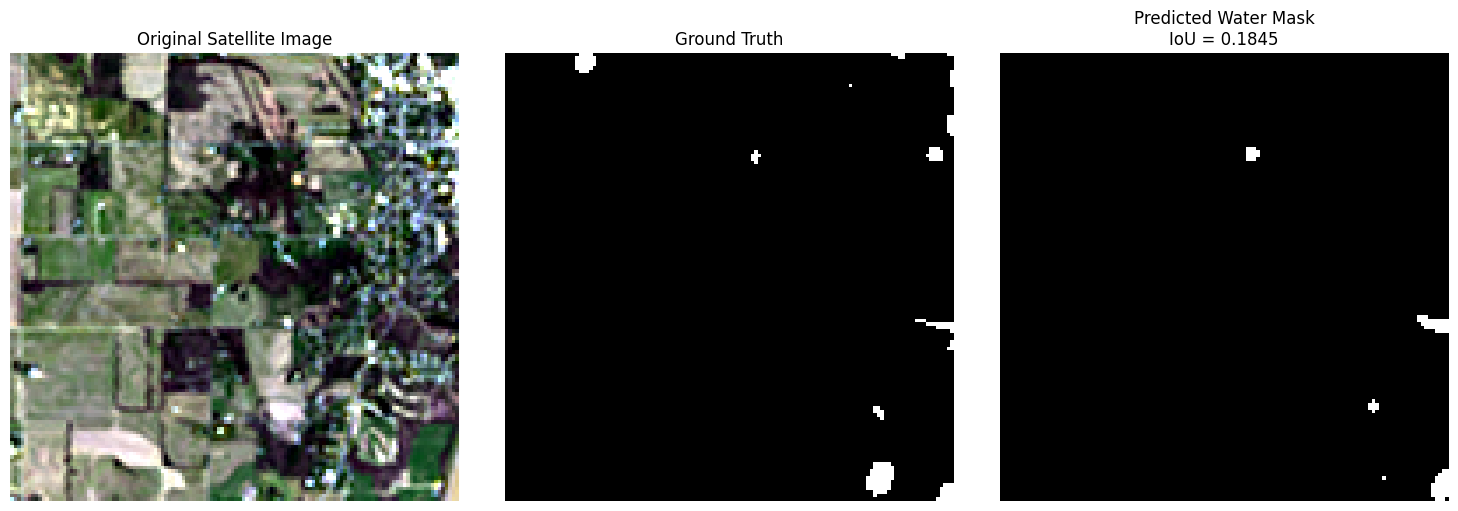


Real image inference completed successfully!


In [8]:

# ============================================================
# CELL 8 — Real Multispectral Image Inference
# ============================================================

import numpy as np
import torch
import matplotlib.pyplot as plt

from src.data import (
    build_file_maps,
    load_raw_image,
    load_binary_mask,
    load_stats,
    load_split
)
from src.preprocessing import (
    preprocess_12ch_benchmark,
    make_rgb_composite
)

# 1. Load original training statistics
STATS = load_stats(ROOT / "config" / "stats.json")

# 2. Load original Week 1/2 dataset split
_, train_df, val_df, test_df = load_split(
    ROOT / "config" / "split_v2.csv"
)

# 3. Match satellite images with ground-truth labels
image_map, mask_map = build_file_maps(
    DATA_ROOT / "images",
    DATA_ROOT / "labels"
)

print("Test samples:", len(test_df))
print("Available image pairs:", len(image_map))

# 4. Select one sample from the held-out test set
sample_id = str(test_df.iloc[0]["Sample_ID"])
raw_image = load_raw_image(image_map[sample_id])
true_mask = load_binary_mask(mask_map[sample_id])

# 5. Apply the ORIGINAL Week 2 preprocessing
processed = preprocess_12ch_benchmark(raw_image, STATS)

assert processed.shape == (12, 128, 128)
assert np.isfinite(processed).all()

# 6. Convert image to model tensor
input_tensor = torch.from_numpy(
    processed
).unsqueeze(0).to(DEVICE)

# 7. Run inference
model.eval()

with torch.inference_mode():
    logits = model(input_tensor)
    probabilities = torch.sigmoid(logits)
    predicted_mask = (
        probabilities >= 0.5
    ).float().squeeze().cpu().numpy()

# 8. Calculate IoU and F1 for this one sample
pred = predicted_mask.astype(bool)
target = true_mask.astype(bool)

tp = np.logical_and(pred, target).sum()
fp = np.logical_and(pred, ~target).sum()
fn = np.logical_and(~pred, target).sum()

iou = (tp + 1e-7) / (tp + fp + fn + 1e-7)
f1 = (2 * tp + 1e-7) / (2 * tp + fp + fn + 1e-7)

print("\nSample ID:", sample_id)
print("Raw image shape:", raw_image.shape)
print("Processed shape:", processed.shape)
print("Prediction shape:", predicted_mask.shape)
print("IoU:", round(float(iou), 4))
print("F1:", round(float(f1), 4))

# 9. Visualization
rgb_image = make_rgb_composite(raw_image)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(rgb_image)
axes[0].set_title("Original Satellite Image")

axes[1].imshow(true_mask, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Ground Truth")

axes[2].imshow(predicted_mask, cmap="gray", vmin=0, vmax=1)
axes[2].set_title(
    f"Predicted Water Mask\nIoU = {iou:.4f}"
)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("\nReal image inference completed successfully!")


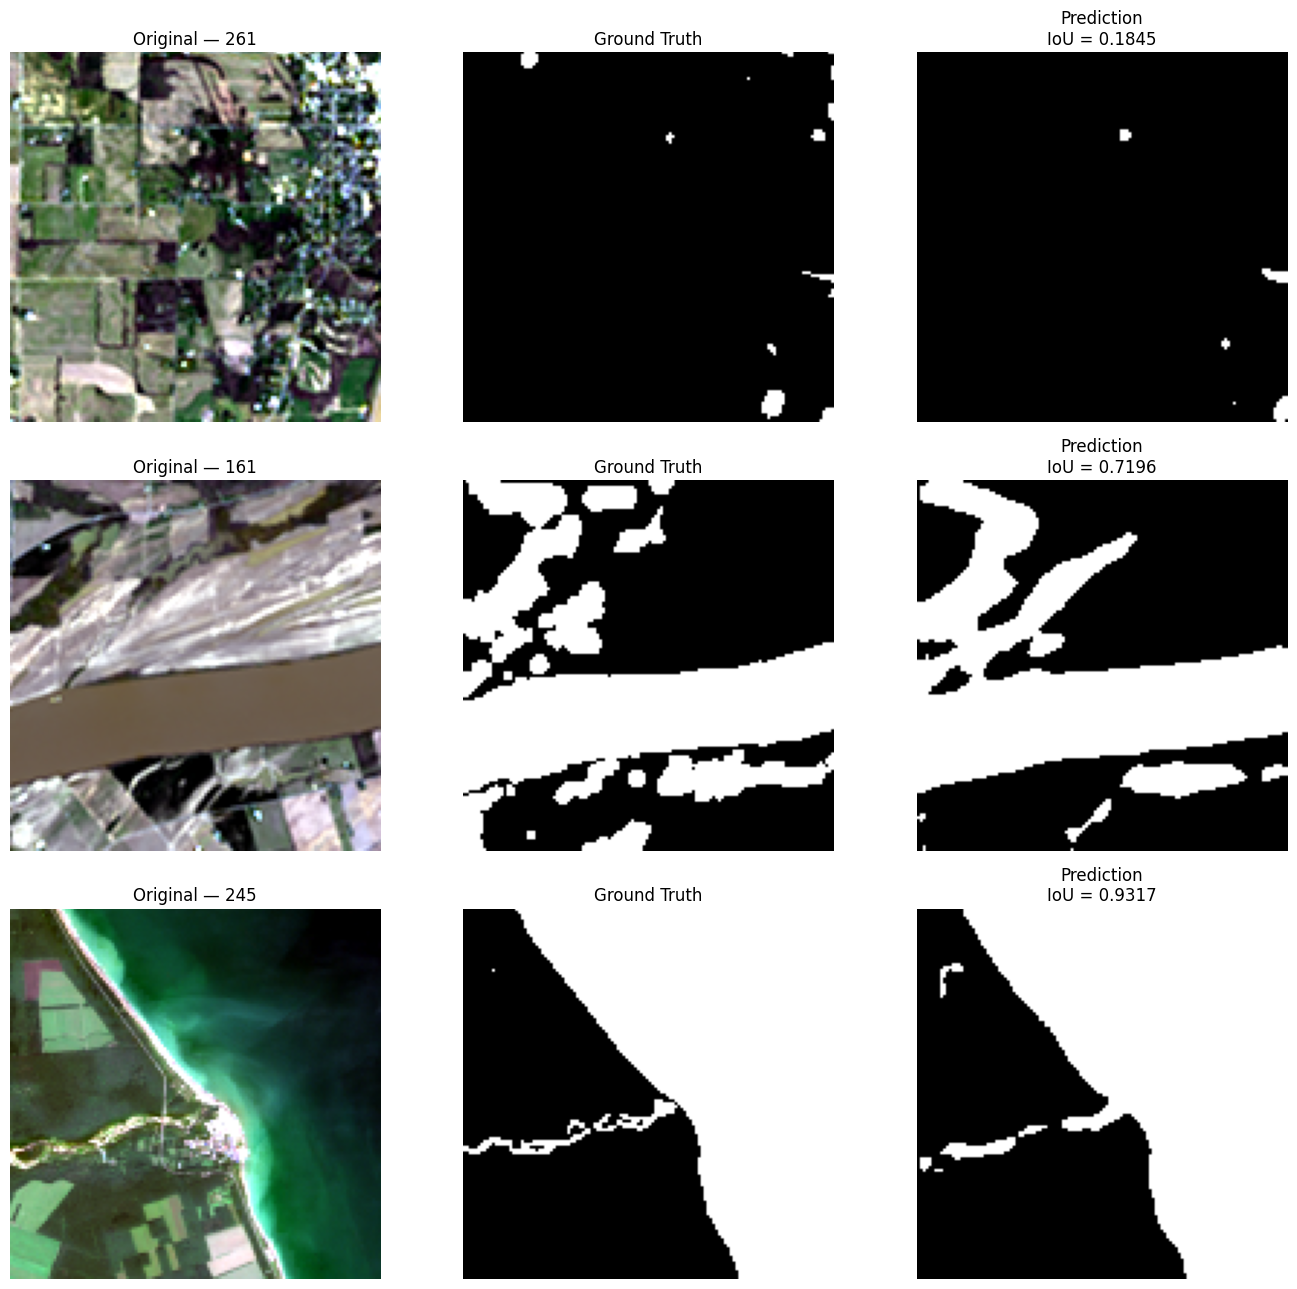


THREE-SAMPLE INFERENCE RESULTS


,Sample_ID,Coverage_Group,True_Water_%,Predicted_Water_%,IoU,Precision,Recall,F1
0,261,Very Low Water,1.14,0.55,0.1845,0.4778,0.2312,0.3116
1,161,Medium Water,42.21,39.70,0.7196,0.8633,0.8121,0.8370
2,245,High Water,52.70,55.34,0.9317,0.9417,0.9888,0.9646



Results saved successfully!


In [10]:

# ============================================================
# CELL 9 — Three Real Test Samples
# ============================================================

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from pathlib import Path

# Select representative samples across water coverage levels
coverage_ranges = [
    ("Very Low Water", 0, 5),
    ("Medium Water", 20, 50),
    ("High Water", 50, 101)
]

results = []

fig, axes = plt.subplots(3, 3, figsize=(14, 13))

model.eval()

for row, (group, low, high) in enumerate(coverage_ranges):

    candidates = test_df[
        (test_df["Water_Percentage"] >= low) &
        (test_df["Water_Percentage"] < high)
    ]

    if candidates.empty:
        raise ValueError(
            f"No test samples found for {group}"
        )

    sample = candidates.iloc[0]
    sample_id = str(int(sample["Sample_ID"]))

    raw = load_raw_image(image_map[sample_id])
    ground_truth = load_binary_mask(mask_map[sample_id])

    # Original Week 2 preprocessing
    processed = preprocess_12ch_benchmark(raw, STATS)

    tensor = torch.from_numpy(
        processed
    ).unsqueeze(0).to(DEVICE)

    # Run inference
    with torch.inference_mode():
        logits = model(tensor)
        probs = torch.sigmoid(logits)
        prediction = (
            probs >= 0.5
        ).squeeze().cpu().numpy().astype(bool)

    target = ground_truth.astype(bool)

    # Calculate metrics
    tp = np.logical_and(prediction, target).sum()
    fp = np.logical_and(prediction, ~target).sum()
    fn = np.logical_and(~prediction, target).sum()

    iou = (tp + 1e-7) / (tp + fp + fn + 1e-7)
    precision = (tp + 1e-7) / (tp + fp + 1e-7)
    recall = (tp + 1e-7) / (tp + fn + 1e-7)
    f1 = (2 * tp + 1e-7) / (2 * tp + fp + fn + 1e-7)

    results.append({
        "Sample_ID": sample_id,
        "Coverage_Group": group,
        "True_Water_%": round(
            float(sample["Water_Percentage"]), 2
        ),
        "Predicted_Water_%": round(
            float(prediction.mean() * 100), 2
        ),
        "IoU": round(float(iou), 4),
        "Precision": round(float(precision), 4),
        "Recall": round(float(recall), 4),
        "F1": round(float(f1), 4)
    })

    # Visualizations
    axes[row, 0].imshow(make_rgb_composite(raw))
    axes[row, 0].set_title(f"Original — {sample_id}")

    axes[row, 1].imshow(
        target, cmap="gray", vmin=0, vmax=1
    )
    axes[row, 1].set_title("Ground Truth")

    axes[row, 2].imshow(
        prediction, cmap="gray", vmin=0, vmax=1
    )
    axes[row, 2].set_title(
        f"Prediction\nIoU = {iou:.4f}"
    )

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

# Create results table
results_df = pd.DataFrame(results)

print("\nTHREE-SAMPLE INFERENCE RESULTS")
display(results_df)

# Save results
output_dir = Path("/kaggle/working/week3_deployment")
output_dir.mkdir(parents=True, exist_ok=True)

results_df.to_csv(
    output_dir / "three_sample_inference_results.csv",
    index=False
)

print("\nResults saved successfully!")


In [11]:

# ============================================================
# CELL 10 — Create Production Inference Script
# ============================================================

from pathlib import Path
import shutil

DEPLOY_DIR = Path("/kaggle/working/week3_deployment")
DEPLOY_DIR.mkdir(parents=True, exist_ok=True)

INFERENCE_CODE = r'''
"""Week 3 - Multispectral Water Segmentation Inference."""

from pathlib import Path
import sys
import numpy as np
import torch
import tifffile
import segmentation_models_pytorch as smp

PROJECT_DIR = Path(__file__).resolve().parent

# Import the original Week 2 preprocessing.
sys.path.insert(0, str(PROJECT_DIR))

from src.preprocessing import (
    preprocess_12ch_benchmark,
    make_rgb_composite,
)
from src.data import load_stats

IMAGE_SHAPE = (12, 128, 128)
THRESHOLD = 0.5


class WaterSegmentationInference:

    def __init__(
        self,
        checkpoint_path=None,
        stats_path=None,
        device=None
    ):
        self.device = torch.device(
            device or (
                "cuda" if torch.cuda.is_available() else "cpu"
            )
        )

        checkpoint_path = Path(
            checkpoint_path
            or PROJECT_DIR / "best_water_segmentation_model.pth"
        )

        stats_path = Path(
            stats_path
            or PROJECT_DIR / "config" / "stats.json"
        )

        if not checkpoint_path.is_file():
            raise FileNotFoundError(
                f"Checkpoint missing: {checkpoint_path}"
            )

        if not stats_path.is_file():
            raise FileNotFoundError(
                f"Training statistics missing: {stats_path}"
            )

        self.stats = load_stats(stats_path)

        # Load the original trained checkpoint.
        checkpoint = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=True
        )

        assert checkpoint["encoder"] == "resnet34"
        assert checkpoint["decoder"] == "unet"
        assert checkpoint["in_channels"] == 12

        self.model = smp.Unet(
            encoder_name="resnet34",
            encoder_weights=None,
            in_channels=12,
            classes=1,
            activation=None
        )

        self.model.load_state_dict(
            checkpoint["model_state_dict"],
            strict=True
        )

        self.model.to(self.device)
        self.model.eval()

        self.checkpoint_info = {
            "encoder": checkpoint["encoder"],
            "decoder": checkpoint["decoder"],
            "strategy": checkpoint["strategy"],
            "seed": checkpoint["seed"],
            "best_epoch": checkpoint["best_epoch"]
        }

    @staticmethod
    def load_image(image_path):
        """Read a genuine 12-band TIFF or NumPy image."""

        path = Path(image_path)

        if path.suffix.lower() in (".tif", ".tiff"):
            image = tifffile.imread(path)

        elif path.suffix.lower() == ".npy":
            image = np.load(path, allow_pickle=False)

        else:
            raise ValueError(
                "Unsupported format. Use .tif, .tiff or .npy"
            )

        # Accept channel-last or channel-first layout.
        if image.shape == (128, 128, 12):
            image = np.transpose(image, (2, 0, 1))

        if image.shape != IMAGE_SHAPE:
            raise ValueError(
                f"Expected 12-channel image {IMAGE_SHAPE}; "
                f"received {image.shape}"
            )

        image = image.astype(np.float32)

        if not np.isfinite(image).all():
            raise ValueError("Input contains NaN or Inf")

        return image

    def predict_array(self, raw_image):
        """Predict a binary water mask from a raw 12-band array."""

        raw_image = np.asarray(raw_image)

        if raw_image.shape != IMAGE_SHAPE:
            raise ValueError(
                f"Expected {IMAGE_SHAPE}, got {raw_image.shape}"
            )

        if not np.isfinite(raw_image).all():
            raise ValueError("Input contains NaN or Inf")

        # EXACT original Week 2 preprocessing.
        processed = preprocess_12ch_benchmark(
            raw_image, self.stats
        )

        tensor = torch.from_numpy(
            np.ascontiguousarray(processed)
        ).unsqueeze(0).to(self.device)

        with torch.inference_mode():
            logits = self.model(tensor)
            probabilities = torch.sigmoid(logits)

            binary_mask = (
                probabilities >= THRESHOLD
            ).squeeze().cpu().numpy().astype(np.uint8)

        if binary_mask.shape != (128, 128):
            raise RuntimeError("Invalid prediction shape")

        return {
            "mask": binary_mask,
            "water_percentage": float(
                binary_mask.mean() * 100
            ),
            "rgb_preview": make_rgb_composite(raw_image)
        }

    def predict_file(self, image_path):
        raw_image = self.load_image(image_path)
        return self.predict_array(raw_image)

    @staticmethod
    def save_mask(mask, output_path):
        """Save a binary mask as a visible black-and-white PNG."""
        from PIL import Image

        output_path = Path(output_path)
        output_path.parent.mkdir(
            parents=True, exist_ok=True
        )

        mask = np.asarray(mask)

        if mask.shape != (128, 128):
            raise ValueError("Invalid mask shape")

        if not np.isin(mask, [0, 1]).all():
            raise ValueError("Mask must contain only 0 and 1")

        Image.fromarray(
            (mask * 255).astype(np.uint8),
            mode="L"
        ).save(output_path)

        return output_path
'''

# Write standalone inference script
inference_file = DEPLOY_DIR / "inference.py"
inference_file.write_text(
    INFERENCE_CODE,
    encoding="utf-8"
)

# Reuse original Week 2 preprocessing modules.
shutil.copytree(
    ROOT / "src",
    DEPLOY_DIR / "src",
    dirs_exist_ok=True
)

# Copy original training statistics.
config_dir = DEPLOY_DIR / "config"
config_dir.mkdir(exist_ok=True)

shutil.copy2(
    ROOT / "config" / "stats.json",
    config_dir / "stats.json"
)

print("=" * 55)
print("PRODUCTION INFERENCE SCRIPT CREATED")
print("=" * 55)

print("File:", inference_file)
print("Source modules copied:", (DEPLOY_DIR / "src").exists())
print("Training statistics copied:", (
    config_dir / "stats.json"
).exists())

print("\nCell 10 completed successfully!")


PRODUCTION INFERENCE SCRIPT CREATED
File: /kaggle/working/week3_deployment/inference.py
Source modules copied: True
Training statistics copied: True

Cell 10 completed successfully!


In [12]:

# ============================================================
# CELL 11 — Verify Standalone Inference
# ============================================================

import sys
import numpy as np
import torch
from pathlib import Path

DEPLOY_DIR = Path("/kaggle/working/week3_deployment")

sys.path.insert(0, str(DEPLOY_DIR))

from inference import WaterSegmentationInference

# Copy the exact model already used in Week 3
import shutil

shutil.copy2(
    CHECKPOINT_PATH,
    DEPLOY_DIR / "best_water_segmentation_model.pth"
)

# Initialize deployment model
predictor = WaterSegmentationInference(
    device="cpu"
)

print("Deployment model loaded!")
print("Configuration:", predictor.checkpoint_info)

# Test using Sample 261
test_id = "261"
sample_path = image_map[test_id]

result = predictor.predict_file(sample_path)

# Compare directly with the notebook model
raw = load_raw_image(sample_path)
processed = preprocess_12ch_benchmark(raw, STATS)

tensor = torch.from_numpy(
    np.ascontiguousarray(processed)
).unsqueeze(0).to(DEVICE)

model.eval()

with torch.inference_mode():
    expected_mask = (
        torch.sigmoid(model(tensor)) >= 0.5
    ).squeeze().cpu().numpy().astype(np.uint8)

assert np.array_equal(
    result["mask"],
    expected_mask
), "Inference mismatch detected!"

assert result["mask"].shape == (128, 128)
assert np.isin(result["mask"], [0, 1]).all()

# Save predicted water mask
mask_path = predictor.save_mask(
    result["mask"],
    DEPLOY_DIR / "sample_261_mask.png"
)

print("\nSample:", test_id)
print("Mask shape:", result["mask"].shape)
print(
    "Water coverage:",
    round(result["water_percentage"], 2),
    "%"
)
print("Saved mask:", mask_path)
print("\nStandalone inference verification PASSED!")


Deployment model loaded!
Configuration: {'encoder': 'resnet34', 'decoder': 'unet', 'strategy': 'rgb_zero_extra', 'seed': 123, 'best_epoch': 61}

Sample: 261
Mask shape: (128, 128)
Water coverage: 0.55 %
Saved mask: /kaggle/working/week3_deployment/sample_261_mask.png

Standalone inference verification PASSED!


In [23]:

# ============================================================
# CELL 19 — Prepare 46 Test Images Gallery
# ============================================================

from pathlib import Path
import json
import shutil
import numpy as np
from PIL import Image

DEPLOY_DIR = Path("/kaggle/working/week3_deployment")

GALLERY_DIR = DEPLOY_DIR / "gallery_samples"
PREVIEW_DIR = DEPLOY_DIR / "static" / "gallery_previews"
MANIFEST_PATH = DEPLOY_DIR / "static" / "gallery_manifest.json"

GALLERY_DIR.mkdir(parents=True, exist_ok=True)
PREVIEW_DIR.mkdir(parents=True, exist_ok=True)

# Confirm that the gallery contains ONLY held-out test images
assert len(test_df) == 46, (
    f"Expected 46 test images, found {len(test_df)}"
)

test_ids = [
    str(sample_id)
    for sample_id in test_df["Sample_ID"].tolist()
]

assert len(test_ids) == len(set(test_ids)), (
    "Duplicate test sample IDs found."
)

def create_preview(raw_image):
    """Convert the original multispectral image to an RGB preview."""
    rgb = np.asarray(make_rgb_composite(raw_image))

    if rgb.ndim != 3 or rgb.shape[-1] != 3:
        raise ValueError(
            f"Invalid RGB preview shape: {rgb.shape}"
        )

    rgb = rgb.astype(np.float32)

    if not np.isfinite(rgb).all():
        raise ValueError("Non-finite values in RGB preview.")

    if rgb.max() <= 1.5 and rgb.min() >= 0:
        rgb = rgb * 255.0

    return np.clip(rgb, 0, 255).astype(np.uint8)

manifest = []

for sample_id in sorted(test_ids, key=int):

    source_path = Path(image_map[sample_id])
    raw_image = load_raw_image(source_path)

    if raw_image.shape != (12, 128, 128):
        raise ValueError(
            f"Sample {sample_id}: invalid shape {raw_image.shape}"
        )

    # Preserve the actual multispectral image for prediction
    extension = source_path.suffix.lower()
    filename = f"sample_{sample_id}{extension}"
    destination = GALLERY_DIR / filename
    shutil.copy2(source_path, destination)

    # RGB preview is only for display, never for model input
    preview = create_preview(raw_image)
    preview_filename = f"sample_{sample_id}.png"

    Image.fromarray(preview).save(
        PREVIEW_DIR / preview_filename
    )

    manifest.append({
        "sample_id": sample_id,
        "filename": filename,
        "preview_url": (
            f"/static/gallery_previews/{preview_filename}"
        ),
        "split": "test"
    })

with open(MANIFEST_PATH, "w", encoding="utf-8") as file:
    json.dump(manifest, file, indent=2)

# Final validation
assert len(manifest) == 46
assert len(list(PREVIEW_DIR.glob("*.png"))) == 46

for item in manifest:
    assert (GALLERY_DIR / item["filename"]).is_file()

print("=" * 55)
print("WATERSEG AI — GALLERY PREPARATION")
print("=" * 55)
print("Test images:", len(manifest))
print("RGB previews:", len(list(PREVIEW_DIR.glob("*.png"))))
print("Gallery manifest:", MANIFEST_PATH)
print("Status: PASSED")


WATERSEG AI — GALLERY PREPARATION
Test images: 46
RGB previews: 46
Gallery manifest: /kaggle/working/week3_deployment/static/gallery_manifest.json
Status: PASSED


In [24]:

# ============================================================
# CELL 20 — Flask API with Gallery & Predictions
# ============================================================

from pathlib import Path
import ast

DEPLOY_DIR = Path("/kaggle/working/week3_deployment")
APP_PATH = DEPLOY_DIR / "app.py"

APP_CODE = r'''
"""WaterSeg AI — Flask REST API and Gallery Backend."""

from io import BytesIO
from pathlib import Path
import base64
import json

import numpy as np
import tifffile
from PIL import Image
from flask import Flask, request, jsonify, render_template

from inference import WaterSegmentationInference
from src.preprocessing import make_rgb_composite

BASE_DIR = Path(__file__).resolve().parent

app = Flask(
    __name__,
    root_path=str(BASE_DIR),
    template_folder=str(BASE_DIR / "templates"),
    static_folder=str(BASE_DIR / "static"),
)

app.config["MAX_CONTENT_LENGTH"] = 20 * 1024 * 1024

# Load the model once at application startup.
predictor = WaterSegmentationInference(device="cpu")

ALLOWED_EXTENSIONS = {".tif", ".tiff", ".npy"}
GALLERY_DIR = BASE_DIR / "gallery_samples"
MANIFEST_PATH = BASE_DIR / "static" / "gallery_manifest.json"

with MANIFEST_PATH.open("r", encoding="utf-8") as file:
    GALLERY = json.load(file)

GALLERY_LOOKUP = {
    str(item["sample_id"]): item for item in GALLERY
}


def encode_png(array, mode="RGB"):
    """Encode an image as a browser-ready PNG data URL."""
    image = Image.fromarray(array.astype(np.uint8), mode=mode)
    buffer = BytesIO()
    image.save(buffer, format="PNG")

    encoded = base64.b64encode(
        buffer.getvalue()
    ).decode("ascii")

    return "data:image/png;base64," + encoded


def prepare_rgb(raw_image):
    """Generate display-only RGB from original 12-band data."""
    rgb = np.asarray(
        make_rgb_composite(raw_image),
        dtype=np.float32
    )

    if rgb.shape != (128, 128, 3):
        raise ValueError(f"Invalid RGB shape: {rgb.shape}")

    if not np.isfinite(rgb).all():
        raise ValueError("RGB preview contains invalid values")

    if rgb.min() >= 0 and rgb.max() <= 1.5:
        rgb = rgb * 255.0

    return np.clip(rgb, 0, 255).astype(np.uint8)


def make_overlay(rgb, binary_mask):
    """Highlight detected water in cyan over RGB."""
    overlay = rgb.astype(np.float32).copy()
    water = binary_mask.astype(bool)

    cyan = np.array([0, 235, 235], dtype=np.float32)
    alpha = 0.55

    overlay[water] = (
        (1 - alpha) * overlay[water]
        + alpha * cyan
    )

    return np.clip(overlay, 0, 255).astype(np.uint8)


def read_uploaded_image(uploaded_file):
    extension = Path(uploaded_file.filename).suffix.lower()

    if extension not in ALLOWED_EXTENSIONS:
        raise ValueError("Unsupported file format: use TIFF or NPY")

    file_bytes = uploaded_file.read()

    if not file_bytes:
        raise ValueError("Uploaded file is empty")

    buffer = BytesIO(file_bytes)

    if extension == ".npy":
        raw = np.load(buffer, allow_pickle=False)
    else:
        raw = tifffile.imread(buffer)

    if raw.shape == (128, 128, 12):
        raw = np.transpose(raw, (2, 0, 1))

    return raw


def prediction_response(raw_image, source, filename, sample_id=None):
    """Predict and return Original, Mask, Overlay and coverage."""
    result = predictor.predict_array(raw_image)

    mask = np.asarray(result["mask"], dtype=np.uint8)

    if mask.shape != (128, 128):
        raise ValueError(f"Invalid prediction shape: {mask.shape}")

    rgb = prepare_rgb(raw_image)
    overlay = make_overlay(rgb, mask)
    mask_png = mask * 255

    return {
        "success": True,
        "source": source,
        "filename": filename,
        "sample_id": sample_id,
        "water_percentage": round(
            float(mask.mean() * 100), 2
        ),
        "original_image": encode_png(rgb, "RGB"),
        "mask_image": encode_png(mask_png, "L"),
        "overlay_image": encode_png(overlay, "RGB"),
    }


@app.get("/")
def index():
    return render_template("index.html")


@app.get("/health")
def health():
    return jsonify({
        "status": "ok",
        "input_shape": [12, 128, 128],
        "gallery_count": len(GALLERY),
        "model": predictor.checkpoint_info
    })


@app.get("/gallery")
def gallery():
    return jsonify({
        "count": len(GALLERY),
        "samples": GALLERY
    })


@app.post("/predict-sample/<sample_id>")
def predict_sample(sample_id):
    item = GALLERY_LOOKUP.get(sample_id)

    if item is None:
        return jsonify({"error": "Sample not found"}), 404

    sample_path = GALLERY_DIR / item["filename"]

    if not sample_path.is_file():
        return jsonify({"error": "Sample file missing"}), 500

    try:
        raw = predictor.load_image(sample_path)

        return jsonify(
            prediction_response(
                raw,
                source="gallery",
                filename=item["filename"],
                sample_id=sample_id
            )
        )

    except (ValueError, TypeError, OSError) as exc:
        return jsonify({"error": str(exc)}), 400


@app.post("/predict")
def predict_upload():
    if "file" not in request.files:
        return jsonify({
            "error": "Missing multipart file field: file"
        }), 400

    uploaded = request.files["file"]

    if not uploaded.filename:
        return jsonify({"error": "No file selected"}), 400

    extension = Path(uploaded.filename).suffix.lower()

    if extension not in ALLOWED_EXTENSIONS:
        return jsonify({
            "error": "Unsupported file format. Use TIFF or NPY."
        }), 415

    try:
        raw = read_uploaded_image(uploaded)

        return jsonify(
            prediction_response(
                raw,
                source="upload",
                filename=uploaded.filename
            )
        )

    except (ValueError, TypeError, OSError) as exc:
        return jsonify({"error": str(exc)}), 400


@app.errorhandler(413)
def file_too_large(error):
    return jsonify({
        "error": "File exceeds 20 MB limit"
    }), 413


if __name__ == "__main__":
    app.run(
        host="127.0.0.1",
        port=5000,
        debug=False
    )
'''

# Verify valid Python before saving.
ast.parse(APP_CODE)

APP_PATH.write_text(APP_CODE, encoding="utf-8")

assert APP_PATH.is_file()

print("=" * 55)
print("WATERSEG AI — FINAL FLASK API")
print("=" * 55)
print("API file:", APP_PATH)
print("Python syntax: PASSED")
print("Gallery endpoint: GET /gallery")
print("Gallery prediction: POST /predict-sample/<sample_id>")
print("External upload: POST /predict")
print("Original + Binary Mask + Overlay: ENABLED")
print("Status: PASSED")


WATERSEG AI — FINAL FLASK API
API file: /kaggle/working/week3_deployment/app.py
Python syntax: PASSED
Gallery endpoint: GET /gallery
Gallery prediction: POST /predict-sample/<sample_id>
External upload: POST /predict
Original + Binary Mask + Overlay: ENABLED
Status: PASSED


In [25]:

# ============================================================
# CELL 21 — Professional WaterSeg AI Frontend
# ============================================================

from pathlib import Path

DEPLOY_DIR = Path("/kaggle/working/week3_deployment")
TEMPLATES = DEPLOY_DIR / "templates"
STATIC = DEPLOY_DIR / "static"

TEMPLATES.mkdir(parents=True, exist_ok=True)
STATIC.mkdir(parents=True, exist_ok=True)

# ============================================================
# 1. HTML
# ============================================================

HTML = r'''
<!DOCTYPE html>
<html lang="en">
<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1">
  <meta name="theme-color" content="#071623">
  <title>WaterSeg AI | Satellite Water Segmentation</title>
  <link rel="stylesheet" href="{{ url_for('static', filename='style.css') }}">
  <script src="{{ url_for('static', filename='script.js') }}" defer></script>
</head>

<body>
  <div class="app-shell">

    <header class="topbar">
      <div class="brand">
        <div class="brand-mark">W<span>·</span></div>
        <div>
          <div class="brand-name">WaterSeg <span>AI</span></div>
          <div class="brand-sub">MULTISPECTRAL INTELLIGENCE</div>
        </div>
      </div>
      <div class="topbar-right">
        <span class="status-dot"></span>
        <span>LOCAL INFERENCE</span>
        <span class="version">WEEK 03 · DEPLOYMENT</span>
      </div>
    </header>

    <section class="hero">
      <div class="eyebrow">SATELLITE IMAGERY / DEEP LEARNING</div>
      <h1>See water.<br><em>Understand the landscape.</em></h1>
      <p>
        Explore satellite imagery using a trained ResNet34 U-Net model.
        Select a test sample or upload your own 12-band image to visualize
        water segmentation results.
      </p>
      <div class="hero-tags">
        <span>12 Spectral Bands</span>
        <span>ResNet34 U-Net</span>
        <span>128 × 128 Resolution</span>
        <span>Binary Segmentation</span>
      </div>
    </section>

    <section class="workspace-heading">
      <div>
        <div class="eyebrow">01 / INPUT WORKSPACE</div>
        <h2>Choose an image</h2>
      </div>
      <div class="workspace-note">Select a sample or upload your own</div>
    </section>

    <section class="input-layout">

      <div class="panel gallery-panel">
        <div class="panel-heading">
          <div>
            <h3>Test Set Gallery</h3>
            <p>Browse the held-out satellite test collection.</p>
          </div>
          <span id="galleryCount" class="count-pill">Loading...</span>
        </div>

        <div class="search-box">
          <span class="search-icon">⌕</span>
          <input
            type="search"
            id="gallerySearch"
            placeholder="Search sample number..."
            aria-label="Search samples by number"
          >
          <button id="clearSearch" class="clear-search" type="button"
                  aria-label="Clear search">×</button>
        </div>

        <div id="galleryGrid" class="gallery-grid">
          <p class="loading-gallery">Loading satellite previews...</p>
        </div>

        <div class="gallery-footer">
          <span id="selectedText">No sample selected</span>
          <button id="analyzeGalleryBtn" type="button" disabled>
            Analyze Selected Image <span>↗</span>
          </button>
        </div>
      </div>

      <div class="panel upload-panel">
        <div class="panel-heading">
          <div>
            <h3>Upload Your Image</h3>
            <p>Run inference on an external satellite file.</p>
          </div>
          <span class="count-pill">CUSTOM INPUT</span>
        </div>

        <label class="upload-dropzone" id="uploadDropzone" for="imageFile">
          <div class="upload-symbol">↑</div>
          <div class="upload-title" id="fileName">Choose an image file</div>
          <div class="upload-description">
            Click here to browse your computer
          </div>
          <div class="format-pills">
            <span>.TIF</span>
            <span>.TIFF</span>
            <span>.NPY</span>
          </div>
          <input
            type="file"
            id="imageFile"
            accept=".tif,.tiff,.npy"
          >
        </label>

        <div class="upload-guidance">
          <div><span>INPUT</span><strong>12 spectral channels</strong></div>
          <div><span>SIZE</span><strong>128 × 128 pixels</strong></div>
          <div><span>LIMIT</span><strong>20 MB maximum</strong></div>
        </div>

        <button id="uploadBtn" class="primary-button" type="button" disabled>
          Analyze Uploaded Image <span>↗</span>
        </button>

        <p class="upload-footnote">
          Ordinary 3-channel RGB photos are not supported.
          Images must use the original training band order and
          compatible multispectral values.
        </p>
      </div>

    </section>

    <section class="workspace-heading results-heading">
      <div>
        <div class="eyebrow">02 / AI SEGMENTATION OUTPUT</div>
        <h2>Analysis results</h2>
      </div>
      <span class="model-label">POWERED BY RESNET34 U-NET</span>
    </section>

    <section class="panel results-panel">

      <div class="results-top">
        <div class="result-info">
          <div id="statusIndicator" class="result-state">READY</div>
          <h3 id="resultTitle">Waiting for analysis</h3>
          <p id="status" role="status" aria-live="polite">
            Choose a gallery image or upload a satellite file to begin.
          </p>
        </div>

        <div class="metric-group">
          <div class="metric">
            <span class="metric-label">PREDICTED WATER COVERAGE</span>
            <strong id="coverage">—</strong>
            <small>Percentage of image classified as water</small>
          </div>
          <div class="metric metric-secondary">
            <span class="metric-label">IMAGE SOURCE</span>
            <strong id="resultSource">—</strong>
            <small id="resultFile">No file analyzed</small>
          </div>
        </div>
      </div>

      <div class="result-grid">

        <article class="result-card">
          <div class="image-label">
            <span class="label-number">01</span>
            <div>
              <h4>Original Satellite Image</h4>
              <p>RGB visualization of the multispectral input</p>
            </div>
          </div>
          <div class="image-frame">
            <img id="originalImage" alt="Original satellite RGB preview" hidden>
            <div id="originalPlaceholder" class="placeholder">
              <span>◫</span>
              <p>Original image preview</p>
            </div>
          </div>
          <a id="downloadOriginal" class="image-download" hidden>
            Download Original Preview ↓
          </a>
        </article>

        <article class="result-card">
          <div class="image-label">
            <span class="label-number">02</span>
            <div>
              <h4>Predicted Water Mask</h4>
              <p>White indicates detected water regions</p>
            </div>
          </div>
          <div class="image-frame">
            <img id="maskImage" alt="Binary predicted water mask" hidden>
            <div id="maskPlaceholder" class="placeholder">
              <span>◫</span>
              <p>Binary mask preview</p>
            </div>
          </div>
          <a id="downloadMask" class="image-download" hidden>
            Download Binary Mask ↓
          </a>
        </article>

        <article class="result-card">
          <div class="image-label">
            <span class="label-number">03</span>
            <div>
              <h4>Water Detection Overlay</h4>
              <p>Cyan highlights predicted water regions</p>
            </div>
          </div>
          <div class="image-frame">
            <img id="overlayImage" alt="Water detection overlay" hidden>
            <div id="overlayPlaceholder" class="placeholder">
              <span>◫</span>
              <p>Segmentation overlay preview</p>
            </div>
          </div>
          <a id="downloadOverlay" class="image-download" hidden>
            Download Overlay ↓
          </a>
        </article>

      </div>

      <div class="result-legend">
        <span><i class="legend-white"></i> White = predicted water</span>
        <span><i class="legend-black"></i> Black = background</span>
        <span><i class="legend-cyan"></i> Cyan = overlay highlight</span>
      </div>

      <div class="result-note">
        <strong>How to interpret the result</strong>
        <p>
          Water Coverage measures the fraction of pixels predicted as water.
          It is not the model's accuracy or IoU score.
        </p>
      </div>

    </section>

    <footer class="footer">
      <span>WaterSeg AI · Multispectral Water Segmentation</span>
      <span>Cellula Technologies · Week 3 Deployment Project</span>
    </footer>

  </div>
</body>
</html>
'''

# ============================================================
# 2. CSS
# ============================================================

CSS = r'''
:root {
  --bg: #071623;
  --panel: #102637;
  --panel-soft: #0c2030;
  --border: #294556;
  --text: #edf7fa;
  --muted: #9ab0bf;
  --aqua: #49ded7;
  --aqua-deep: #1aa8a9;
  --white: #ffffff;
  --radius: 19px;
  font-family: "Segoe UI", Inter, Arial, sans-serif;
}

* { box-sizing: border-box; }

body {
  margin: 0;
  min-height: 100vh;
  background: var(--bg);
  color: var(--text);
}

button, input { font: inherit; }
button { cursor: pointer; }
button:disabled { cursor: not-allowed; opacity: .45; }

[hidden] { display: none !important; }

.app-shell {
  width: min(1450px, calc(100% - 56px));
  margin: auto;
}

.topbar {
  min-height: 94px;
  display: flex;
  align-items: center;
  justify-content: space-between;
  gap: 18px;
  border-bottom: 1px solid var(--border);
}

.brand { display: flex; align-items: center; gap: 13px; }
.brand-mark {
  width: 48px;
  height: 48px;
  background: var(--aqua);
  color: #06202b;
  display: grid;
  place-items: center;
  border-radius: 14px;
  font-size: 26px;
  font-weight: 900;
}
.brand-mark span { color: #138b92; }
.brand-name { font-size: 23px; font-weight: 800; }
.brand-name span { color: var(--aqua); }
.brand-sub {
  margin-top: 4px;
  font-size: 10px;
  font-weight: 700;
  color: var(--muted);
  letter-spacing: 2px;
}

.topbar-right {
  display: flex;
  align-items: center;
  gap: 10px;
  font-size: 11px;
  color: var(--muted);
  letter-spacing: 1px;
}
.status-dot {
  width: 9px;
  height: 9px;
  background: var(--aqua);
  border-radius: 50%;
  box-shadow: 0 0 13px rgba(73,222,215,.6);
}
.version {
  border-left: 1px solid var(--border);
  padding-left: 18px;
  margin-left: 8px;
}

.hero {
  padding: 57px 0 52px;
  border-bottom: 1px solid var(--border);
}
.eyebrow {
  color: var(--aqua);
  font-size: 11px;
  font-weight: 800;
  letter-spacing: 2px;
}
.hero h1 {
  margin: 18px 0 17px;
  font-size: clamp(38px, 5.6vw, 69px);
  line-height: 1.12;
  letter-spacing: -2px;
}
.hero h1 em {
  font-style: normal;
  color: var(--aqua);
}
.hero p {
  max-width: 760px;
  font-size: 15px;
  line-height: 1.9;
  color: var(--muted);
}
.hero-tags {
  display: flex;
  flex-wrap: wrap;
  gap: 10px;
  margin-top: 25px;
}
.hero-tags span {
  border: 1px solid var(--border);
  background: #0b2233;
  border-radius: 100px;
  padding: 9px 14px;
  font-size: 11px;
  color: #b8cedb;
}

.workspace-heading {
  margin: 43px 0 19px;
  display: flex;
  justify-content: space-between;
  align-items: end;
  gap: 15px;
}
.workspace-heading h2 {
  font-size: 29px;
  margin: 8px 0 0;
}
.workspace-note, .model-label {
  color: var(--muted);
  font-size: 12px;
}

.input-layout {
  display: grid;
  grid-template-columns: minmax(0, 1.5fr) minmax(320px, 1fr);
  gap: 20px;
}
.panel {
  min-width: 0;
  border: 1px solid var(--border);
  border-radius: var(--radius);
  background: var(--panel);
  padding: 25px;
}
.panel-heading {
  display: flex;
  justify-content: space-between;
  gap: 14px;
  align-items: start;
}
.panel-heading h3 { margin: 0 0 8px; font-size: 21px; }
.panel-heading p {
  margin: 0;
  color: var(--muted);
  line-height: 1.6;
  font-size: 13px;
}
.count-pill {
  flex-shrink: 0;
  border: 1px solid #306374;
  color: var(--aqua);
  background: #0b303d;
  padding: 9px 11px;
  font-size: 10px;
  border-radius: 100px;
  font-weight: 800;
}

.search-box {
  margin: 22px 0 16px;
  display: flex;
  align-items: center;
  background: var(--panel-soft);
  border: 1px solid var(--border);
  border-radius: 11px;
  padding: 0 12px;
}
.search-box:focus-within { border-color: var(--aqua); }
.search-icon {
  color: var(--aqua);
  font-size: 27px;
  line-height: 1;
}
.search-box input {
  width: 100%;
  padding: 13px 10px;
  background: none;
  border: none;
  outline: none;
  color: var(--text);
  font-size: 13px;
}
.search-box input::placeholder { color: #7f9cad; }
.clear-search {
  background: transparent;
  color: var(--muted);
  border: none;
  font-size: 21px;
}

.gallery-grid {
  min-height: 250px;
  max-height: 460px;
  overflow-y: auto;
  display: grid;
  grid-template-columns: repeat(4, minmax(0, 1fr));
  align-content: start;
  gap: 12px;
  padding: 2px 5px 6px 0;
}
.gallery-grid::-webkit-scrollbar { width: 7px; }
.gallery-grid::-webkit-scrollbar-thumb {
  background: #31566b;
  border-radius: 10px;
}

.gallery-card {
  min-width: 0;
  border-radius: 12px;
  border: 2px solid transparent;
  background: var(--panel-soft);
  padding: 7px;
  text-align: left;
  color: var(--text);
  transition: border-color .18s, background .18s;
}
.gallery-card:hover { border-color: #54849a; }
.gallery-card.selected {
  border-color: var(--aqua);
  background: #103b48;
}
.gallery-card img {
  display: block;
  width: 100%;
  aspect-ratio: 1/1;
  object-fit: cover;
  border-radius: 8px;
}
.gallery-card strong {
  display: block;
  margin: 9px 2px 5px;
  font-size: 12px;
}
.gallery-card small {
  display: block;
  margin: 0 2px 4px;
  font-size: 10px;
  color: var(--muted);
}
.loading-gallery, .gallery-empty {
  color: var(--muted);
  font-size: 13px;
  line-height: 1.6;
}

.gallery-footer {
  display: flex;
  align-items: center;
  justify-content: space-between;
  gap: 14px;
  border-top: 1px solid var(--border);
  padding-top: 20px;
  margin-top: 18px;
}
.gallery-footer > span {
  font-size: 12px;
  color: var(--muted);
}
.gallery-footer button,
.primary-button {
  background: var(--aqua);
  color: #05222b;
  border: none;
  border-radius: 11px;
  padding: 13px 18px;
  font-size: 12px;
  font-weight: 800;
}
.gallery-footer button span,
.primary-button span { margin-left: 10px; }

.upload-dropzone {
  display: flex;
  flex-direction: column;
  justify-content: center;
  align-items: center;
  gap: 12px;
  margin-top: 24px;
  padding: 23px;
  min-height: 263px;
  text-align: center;
  background: var(--panel-soft);
  border: 2px dashed #37627a;
  border-radius: 15px;
  cursor: pointer;
  transition: border-color .2s;
}
.upload-dropzone:hover { border-color: var(--aqua); }
.upload-dropzone input { display: none; }
.upload-symbol {
  display: grid;
  place-items: center;
  width: 61px;
  height: 61px;
  background: #123a4a;
  color: var(--aqua);
  border-radius: 15px;
  font-size: 34px;
}
.upload-title {
  font-size: 15px;
  font-weight: 800;
  overflow-wrap: anywhere;
}
.upload-description {
  font-size: 12px;
  color: var(--muted);
}
.format-pills { display: flex; gap: 7px; margin-top: 3px; }
.format-pills span {
  padding: 7px 11px;
  border-radius: 7px;
  border: 1px solid var(--border);
  color: var(--aqua);
  font-size: 10px;
  font-weight: 800;
}
.upload-guidance {
  display: grid;
  gap: 13px;
  padding: 21px 0;
}
.upload-guidance div {
  display: flex;
  justify-content: space-between;
  gap: 10px;
  font-size: 11px;
}
.upload-guidance span { color: var(--muted); }
.upload-guidance strong { font-weight: 700; }
.primary-button { width: 100%; padding: 16px; }
.upload-footnote {
  margin: 15px 0 0;
  font-size: 11px;
  color: var(--muted);
  line-height: 1.7;
}

.results-heading { margin-top: 55px; }
.results-panel { padding: 28px; }
.results-top {
  display: flex;
  justify-content: space-between;
  align-items: center;
  flex-wrap: wrap;
  gap: 22px;
  padding-bottom: 27px;
  border-bottom: 1px solid var(--border);
}
.result-info { min-width: 0; flex: 1; }
.result-state {
  display: inline-block;
  color: var(--aqua);
  font-size: 10px;
  font-weight: 800;
  letter-spacing: 1.5px;
}
.result-info h3 {
  font-size: 24px;
  margin: 11px 0;
}
.result-info p {
  margin: 0;
  color: var(--muted);
  font-size: 12px;
  line-height: 1.7;
}

.metric-group {
  display: flex;
  flex-wrap: wrap;
  gap: 12px;
}
.metric {
  width: 230px;
  padding: 17px;
  background: var(--panel-soft);
  border: 1px solid var(--border);
  border-radius: 12px;
}
.metric-secondary { width: 195px; }
.metric-label {
  display: block;
  color: var(--muted);
  font-size: 9px;
  letter-spacing: 1px;
}
.metric strong {
  display: block;
  font-size: 29px;
  margin: 12px 0 6px;
  color: var(--aqua);
  overflow-wrap: anywhere;
}
.metric-secondary strong {
  font-size: 21px;
  color: var(--text);
}
.metric small {
  display: block;
  color: var(--muted);
  font-size: 10px;
  line-height: 1.5;
  overflow-wrap: anywhere;
}

.result-grid {
  display: grid;
  grid-template-columns: repeat(3, minmax(0, 1fr));
  gap: 18px;
  margin-top: 25px;
}
.result-card {
  min-width: 0;
  background: var(--panel-soft);
  border: 1px solid var(--border);
  border-radius: 15px;
  padding: 15px;
}
.image-label {
  display: flex;
  gap: 11px;
  align-items: center;
  min-height: 55px;
  margin-bottom: 14px;
}
.label-number {
  flex-shrink: 0;
  display: grid;
  place-items: center;
  width: 33px;
  height: 33px;
  border-radius: 9px;
  color: var(--aqua);
  background: #113946;
  font-size: 12px;
  font-weight: 800;
}
.image-label h4 { margin: 0 0 6px; font-size: 13px; }
.image-label p {
  margin: 0;
  font-size: 10px;
  color: var(--muted);
  line-height: 1.5;
}

.image-frame {
  display: flex;
  align-items: center;
  justify-content: center;
  overflow: hidden;
  aspect-ratio: 1/1;
  background: #06141e;
  border-radius: 11px;
}
.image-frame img {
  display: block;
  width: 100%;
  height: 100%;
  object-fit: contain;
  image-rendering: pixelated;
}
.placeholder { text-align: center; color: #7292a3; }
.placeholder span {
  display: block;
  font-size: 39px;
  margin-bottom: 10px;
  opacity: .5;
}
.placeholder p { font-size: 12px; }

.image-download {
  display: block;
  margin-top: 13px;
  text-align: center;
  padding: 12px;
  background: #173b49;
  border: 1px solid #306271;
  border-radius: 9px;
  color: var(--aqua);
  text-decoration: none;
  font-size: 11px;
  font-weight: 750;
}
.image-download:hover { background: #1b4b5a; }

.result-legend {
  display: flex;
  flex-wrap: wrap;
  gap: 23px;
  padding: 21px 0;
  font-size: 11px;
  color: var(--muted);
}
.result-legend span { display: flex; align-items: center; gap: 8px; }
.result-legend i {
  display: inline-block;
  width: 11px;
  height: 11px;
  border-radius: 3px;
}
.legend-white { background: #fff; }
.legend-black { background: #000; border: 1px solid #69808f; }
.legend-cyan { background: #00ebeb; }

.result-note {
  border-top: 1px solid var(--border);
  padding-top: 19px;
}
.result-note strong { font-size: 12px; }
.result-note p {
  font-size: 12px;
  color: var(--muted);
  line-height: 1.7;
  margin-bottom: 0;
}

.footer {
  padding: 30px 0;
  margin-top: 35px;
  border-top: 1px solid var(--border);
  display: flex;
  justify-content: space-between;
  flex-wrap: wrap;
  gap: 12px;
  color: #7794a5;
  font-size: 11px;
}

@media (max-width: 1100px) {
  .input-layout { grid-template-columns: 1fr; }
  .gallery-grid { grid-template-columns: repeat(5, minmax(0,1fr)); }
}
@media (max-width: 780px) {
  .result-grid { grid-template-columns: 1fr; }
  .image-frame { max-height: 390px; }
  .gallery-grid { grid-template-columns: repeat(3, minmax(0,1fr)); }
  .metric { width: 100%; }
}
@media (max-width: 520px) {
  .app-shell { width: calc(100% - 28px); }
  .hero { padding: 39px 0; }
  .hero h1 { letter-spacing: -1px; }
  .panel { padding: 17px; }
  .gallery-grid { grid-template-columns: repeat(2, minmax(0,1fr)); }
  .gallery-footer { flex-direction: column; align-items: stretch; }
  .gallery-footer button { width: 100%; }
  .topbar-right .version { display: none; }
  .workspace-heading { align-items: start; }
  .model-label, .workspace-note { display: none; }
  .metric-group { width: 100%; }
}
'''

# ============================================================
# 3. JAVASCRIPT
# ============================================================

JS = r'''
"use strict";

const $ = (id) => document.getElementById(id);

const galleryGrid = $("galleryGrid");
const galleryCount = $("galleryCount");
const gallerySearch = $("gallerySearch");
const selectedText = $("selectedText");
const galleryButton = $("analyzeGalleryBtn");

const fileInput = $("imageFile");
const fileName = $("fileName");
const uploadButton = $("uploadBtn");

const statusText = $("status");
const statusIndicator = $("statusIndicator");
const resultTitle = $("resultTitle");
const coverage = $("coverage");
const resultSource = $("resultSource");
const resultFile = $("resultFile");

let gallerySamples = [];
let selectedSampleId = null;
let busy = false;

function setStatus(message, state = "READY") {
  statusText.textContent = message;
  statusIndicator.textContent = state;
}

function setBusy(value) {
  busy = value;
  galleryButton.disabled = busy || !selectedSampleId;
  uploadButton.disabled = busy || !fileInput.files.length;
}

function resetResults() {
  for (const key of ["original", "mask", "overlay"]) {
    const image = $(key + "Image");
    const placeholder = $(key + "Placeholder");

    image.hidden = true;
    image.removeAttribute("src");
    placeholder.hidden = false;
  }

  for (const key of ["Original", "Mask", "Overlay"]) {
    const link = $("download" + key);
    link.hidden = true;
    link.removeAttribute("href");
  }

  coverage.textContent = "—";
  resultSource.textContent = "—";
  resultFile.textContent = "No file analyzed";
  resultTitle.textContent = "Waiting for analysis";
}

function showResultImage(key, dataUrl, filename) {
  const image = $(key + "Image");
  const placeholder = $(key + "Placeholder");

  image.src = dataUrl;
  image.hidden = false;
  placeholder.hidden = true;

  const title = key.charAt(0).toUpperCase() + key.slice(1);
  const link = $("download" + title);

  link.href = dataUrl;
  link.download = filename;
  link.hidden = false;
}

function displayResult(data) {
  resetResults();

  const baseName = data.sample_id
    ? "sample_" + data.sample_id
    : "uploaded_satellite";

  showResultImage(
    "original",
    data.original_image,
    baseName + "_original.png"
  );

  showResultImage(
    "mask",
    data.mask_image,
    baseName + "_mask.png"
  );

  showResultImage(
    "overlay",
    data.overlay_image,
    baseName + "_overlay.png"
  );

  coverage.textContent = Number(data.water_percentage).toFixed(2) + "%";
  resultSource.textContent = data.source === "gallery"
    ? "Gallery"
    : "Upload";

  resultFile.textContent = data.filename || "Satellite image";

  resultTitle.textContent = data.sample_id
    ? "Sample " + data.sample_id + " analyzed"
    : "Uploaded image analyzed";

  setStatus("Segmentation completed successfully.", "COMPLETED");

  $("resultTitle").scrollIntoView({
    behavior: "smooth",
    block: "center"
  });
}

function createGalleryCard(sample) {
  const button = document.createElement("button");
  button.type = "button";
  button.className = "gallery-card";
  button.dataset.sampleId = String(sample.sample_id);

  const image = document.createElement("img");
  image.src = sample.preview_url;
  image.alt = "Satellite sample " + sample.sample_id;
  image.loading = "lazy";

  const title = document.createElement("strong");
  title.textContent = "Sample " + sample.sample_id;

  const description = document.createElement("small");
  description.textContent = "TEST DATASET";

  button.append(image, title, description);

  button.setAttribute(
    "aria-pressed",
    String(selectedSampleId === String(sample.sample_id))
  );

  if (selectedSampleId === String(sample.sample_id)) {
    button.classList.add("selected");
  }

  button.addEventListener("click", () => {
    if (busy) return;

    selectedSampleId = String(sample.sample_id);

    document.querySelectorAll(".gallery-card").forEach(card => {
      const isSelected = card.dataset.sampleId === selectedSampleId;
      card.classList.toggle("selected", isSelected);
      card.setAttribute("aria-pressed", String(isSelected));
    });

    selectedText.textContent = "Selected: Sample " + selectedSampleId;
    galleryButton.disabled = false;

    setStatus(
      "Sample " + selectedSampleId + " selected. Ready for analysis."
    );
  });

  return button;
}

function renderGallery() {
  const query = gallerySearch.value.trim().toLowerCase();

  const filtered = gallerySamples.filter(sample =>
    String(sample.sample_id).toLowerCase().includes(query)
  );

  galleryGrid.replaceChildren();

  if (!filtered.length) {
    const message = document.createElement("p");
    message.className = "gallery-empty";
    message.textContent = "No samples match your search.";
    galleryGrid.appendChild(message);
  } else {
    const fragment = document.createDocumentFragment();

    filtered.forEach(sample => {
      fragment.appendChild(createGalleryCard(sample));
    });

    galleryGrid.appendChild(fragment);
  }

  galleryCount.textContent =
    filtered.length + " / " + gallerySamples.length + " SAMPLES";
}

async function loadGallery() {
  try {
    const response = await fetch("/gallery");

    if (!response.ok) {
      throw new Error("Gallery endpoint returned " + response.status);
    }

    const data = await response.json();

    if (!Array.isArray(data.samples)) {
      throw new Error("Invalid gallery response.");
    }

    gallerySamples = data.samples;
    renderGallery();
  } catch (error) {
    galleryCount.textContent = "UNAVAILABLE";
    galleryGrid.textContent = "Failed to load gallery: " + error.message;
  }
}

async function handleResponse(response) {
  const data = await response.json();

  if (!response.ok) {
    throw new Error(data.error || "Prediction failed.");
  }

  if (!data.success) {
    throw new Error("The API did not return a successful prediction.");
  }

  return data;
}

galleryButton.addEventListener("click", async () => {
  if (!selectedSampleId || busy) return;

  const sampleId = selectedSampleId;
  setBusy(true);
  resetResults();

  setStatus(
    "Running model inference on Sample " + sampleId + "...",
    "PROCESSING"
  );

  try {
    const response = await fetch(
      "/predict-sample/" + encodeURIComponent(sampleId),
      { method: "POST" }
    );

    const data = await handleResponse(response);
    displayResult(data);
  } catch (error) {
    setStatus("Error: " + error.message, "FAILED");
  } finally {
    setBusy(false);
  }
});

fileInput.addEventListener("change", () => {
  const file = fileInput.files[0];

  fileName.textContent = file ? file.name : "Choose an image file";
  uploadButton.disabled = busy || !file;

  if (file) {
    setStatus("File selected: " + file.name + ". Ready for analysis.");
  }
});

uploadButton.addEventListener("click", async () => {
  const file = fileInput.files[0];
  if (!file || busy) return;

  if (file.size > 20 * 1024 * 1024) {
    setStatus("File exceeds the 20 MB upload limit.", "FAILED");
    return;
  }

  setBusy(true);
  resetResults();
  setStatus("Uploading image and running inference...", "PROCESSING");

  try {
    const formData = new FormData();
    formData.append("file", file);

    const response = await fetch("/predict", {
      method: "POST",
      body: formData
    });

    const data = await handleResponse(response);
    displayResult(data);
  } catch (error) {
    setStatus("Error: " + error.message, "FAILED");
  } finally {
    setBusy(false);
  }
});

gallerySearch.addEventListener("input", renderGallery);

$("clearSearch").addEventListener("click", () => {
  gallerySearch.value = "";
  renderGallery();
  gallerySearch.focus();
});

resetResults();
loadGallery();
'''

# ============================================================
# 4. SAVE FILES
# ============================================================

html_path = TEMPLATES / "index.html"
css_path = STATIC / "style.css"
js_path = STATIC / "script.js"

html_path.write_text(HTML, encoding="utf-8")
css_path.write_text(CSS, encoding="utf-8")
js_path.write_text(JS, encoding="utf-8")

# ============================================================
# 5. VERIFY FILES
# ============================================================

for path in [html_path, css_path, js_path]:
    assert path.is_file()
    assert path.stat().st_size > 0

assert 'id="galleryGrid"' in HTML
assert 'id="originalImage"' in HTML
assert 'id="maskImage"' in HTML
assert 'id="overlayImage"' in HTML

assert '"/gallery"' in JS
assert '"/predict"' in JS
assert '"/predict-sample/"' in JS

print("=" * 60)
print("WATERSEG AI — PROFESSIONAL FRONTEND")
print("=" * 60)
print("HTML:", html_path)
print("CSS:", css_path)
print("JavaScript:", js_path)
print("46-image Gallery UI: READY")
print("Sample Search: READY")
print("External Upload UI: READY")
print("Original + Mask + Overlay: READY")
print("Result Downloads: READY")
print("Responsive Layout: READY")
print("File checks: PASSED")
print("=" * 60)


WATERSEG AI — PROFESSIONAL FRONTEND
HTML: /kaggle/working/week3_deployment/templates/index.html
CSS: /kaggle/working/week3_deployment/static/style.css
JavaScript: /kaggle/working/week3_deployment/static/script.js
46-image Gallery UI: READY
Sample Search: READY
External Upload UI: READY
Original + Mask + Overlay: READY
Result Downloads: READY
Responsive Layout: READY
File checks: PASSED


In [26]:

# ============================================================
# CELL 22 — Final Integration & API Tests
# ============================================================

from pathlib import Path
from io import BytesIO
import sys
import json
import base64
import importlib

import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import display

DEPLOY_DIR = Path("/kaggle/working/week3_deployment")
TEST_DIR = DEPLOY_DIR / "api_test_results"
TEST_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Import the latest Flask application
# ------------------------------------------------------------

if str(DEPLOY_DIR) not in sys.path:
    sys.path.insert(0, str(DEPLOY_DIR))

sys.modules.pop("app", None)
importlib.invalidate_caches()

flask_module = importlib.import_module("app")

assert Path(flask_module.__file__).resolve() == (
    DEPLOY_DIR / "app.py"
).resolve()

app = flask_module.app
client = app.test_client()
predictor = flask_module.predictor

print("=" * 60)
print("WATERSEG AI — FINAL INTEGRATION TESTS")
print("=" * 60)

# ------------------------------------------------------------
# 2. Homepage, CSS, JavaScript and Health
# ------------------------------------------------------------

response = client.get("/")
assert response.status_code == 200
assert b"WaterSeg" in response.data
assert b'galleryGrid' in response.data
assert b'originalImage' in response.data
assert b'overlayImage' in response.data
print("PASS | Homepage")

response = client.get("/static/style.css")
assert response.status_code == 200
assert b".gallery-grid" in response.data
print("PASS | CSS")

response = client.get("/static/script.js")
assert response.status_code == 200
assert b"/predict-sample/" in response.data
print("PASS | JavaScript")

response = client.get("/health")
assert response.status_code == 200
health_data = response.get_json()

assert health_data["status"] == "ok"
assert health_data["gallery_count"] == 46
assert health_data["input_shape"] == [12, 128, 128]
print("PASS | Health endpoint")

# ------------------------------------------------------------
# 3. Verify all 46 gallery images
# ------------------------------------------------------------

response = client.get("/gallery")
assert response.status_code == 200

gallery_data = response.get_json()
samples = gallery_data["samples"]

assert gallery_data["count"] == 46
assert len(samples) == 46

actual_ids = {str(s["sample_id"]) for s in samples}
expected_ids = {
    str(s) for s in test_df["Sample_ID"].tolist()
}

assert actual_ids == expected_ids
assert len(actual_ids) == 46

for sample in samples:
    assert sample["split"] == "test"

    image_path = (
        DEPLOY_DIR / "gallery_samples" / sample["filename"]
    )
    assert image_path.is_file()

    preview_response = client.get(sample["preview_url"])
    assert preview_response.status_code == 200

    preview = Image.open(BytesIO(preview_response.data))
    assert preview.size == (128, 128)
    assert preview.mode == "RGB"

print("PASS | All 46 gallery images and previews")

# ------------------------------------------------------------
# 4. Helpers for prediction verification
# ------------------------------------------------------------

def decode_png(data_url):
    assert data_url.startswith("data:image/png;base64,")
    encoded = data_url.split(",", 1)[1]
    image_bytes = base64.b64decode(encoded)
    return Image.open(BytesIO(image_bytes)).copy()


def check_prediction(data, sample_path):
    assert data["success"] is True

    original = decode_png(data["original_image"])
    mask_image = decode_png(data["mask_image"])
    overlay = decode_png(data["overlay_image"])

    assert original.size == (128, 128)
    assert mask_image.size == (128, 128)
    assert overlay.size == (128, 128)

    assert original.mode == "RGB"
    assert overlay.mode == "RGB"

    mask = np.asarray(mask_image.convert("L"))

    assert mask.shape == (128, 128)
    assert np.isin(mask, [0, 255]).all()

    # Independent standalone inference
    standalone = predictor.predict_file(sample_path)
    expected_mask = standalone["mask"] * 255

    assert np.array_equal(mask, expected_mask), (
        "API prediction differs from standalone inference"
    )

    predicted_coverage = float((mask > 0).mean() * 100)

    assert abs(
        data["water_percentage"] - predicted_coverage
    ) <= 0.02

    return mask


# ------------------------------------------------------------
# 5. Predict three real gallery samples
# ------------------------------------------------------------

sample_ids = ["261", "161", "245"]
results = []

for sample_id in sample_ids:

    response = client.post(
        f"/predict-sample/{sample_id}"
    )

    assert response.status_code == 200, (
        f"Gallery sample {sample_id}: "
        f"{response.status_code} - {response.data[:300]}"
    )

    data = response.get_json()

    assert data["source"] == "gallery"
    assert data["sample_id"] == sample_id

    mask = check_prediction(
        data,
        image_map[sample_id]
    )

    # Save returned PNG mask
    mask_path = TEST_DIR / f"gallery_mask_{sample_id}.png"
    Image.fromarray(mask).save(mask_path)

    target = load_binary_mask(
        mask_map[sample_id]
    ).astype(bool)

    predicted = mask > 0

    tp = np.logical_and(predicted, target).sum()
    fp = np.logical_and(predicted, ~target).sum()
    fn = np.logical_and(~predicted, target).sum()

    iou = (tp + 1e-7) / (tp + fp + fn + 1e-7)
    f1 = (2 * tp + 1e-7) / (
        2 * tp + fp + fn + 1e-7
    )

    results.append({
        "Sample_ID": sample_id,
        "HTTP_Status": response.status_code,
        "Predicted_Water_%": data["water_percentage"],
        "IoU": round(float(iou), 4),
        "F1": round(float(f1), 4),
        "Matches_Standalone": True,
        "Original_Mask_Overlay": True
    })

    print(
        f"PASS | Gallery Sample {sample_id} | "
        f"Coverage: {data['water_percentage']:.2f}% | "
        f"IoU: {iou:.4f}"
    )

results_df = pd.DataFrame(results)
display(results_df)

results_df.to_csv(
    TEST_DIR / "api_test_summary.csv",
    index=False
)

# ------------------------------------------------------------
# 6. Test external TIFF upload
# ------------------------------------------------------------

sample_path = Path(image_map["161"])

with sample_path.open("rb") as file:
    response = client.post(
        "/predict",
        data={
            "file": (
                BytesIO(file.read()),
                "external_sample_161.tif"
            )
        },
        content_type="multipart/form-data"
    )

assert response.status_code == 200, response.data[:300]

upload_data = response.get_json()
assert upload_data["source"] == "upload"

check_prediction(upload_data, sample_path)

print("PASS | External TIFF upload")

# ------------------------------------------------------------
# 7. Test external NPY upload
# ------------------------------------------------------------

raw_image = load_raw_image(image_map["245"])

npy_buffer = BytesIO()
np.save(npy_buffer, raw_image)
npy_buffer.seek(0)

response = client.post(
    "/predict",
    data={
        "file": (npy_buffer, "external_sample.npy")
    },
    content_type="multipart/form-data"
)

assert response.status_code == 200, response.data[:300]

npy_data = response.get_json()

check_prediction(npy_data, image_map["245"])

print("PASS | External NPY upload")

# ------------------------------------------------------------
# 8. Error handling tests
# ------------------------------------------------------------

error_results = []

def check_error(name, response, expected_status):
    passed = response.status_code == expected_status

    error_results.append({
        "Test": name,
        "Expected": expected_status,
        "Actual": response.status_code,
        "Passed": passed
    })

    print(
        f"{'PASS' if passed else 'FAIL'} | "
        f"{name} | HTTP {response.status_code}"
    )


# Missing file
response = client.post(
    "/predict",
    data={},
    content_type="multipart/form-data"
)
check_error("Missing file", response, 400)

# Empty filename
response = client.post(
    "/predict",
    data={"file": (BytesIO(b""), "")},
    content_type="multipart/form-data"
)
check_error("Empty filename", response, 400)

# Unsupported format
response = client.post(
    "/predict",
    data={"file": (BytesIO(b"invalid"), "test.txt")},
    content_type="multipart/form-data"
)
check_error("Unsupported format", response, 415)

# Invalid RGB input
rgb_buffer = BytesIO()
np.save(
    rgb_buffer,
    np.zeros((128, 128, 3), dtype=np.float32)
)
rgb_buffer.seek(0)

response = client.post(
    "/predict",
    data={"file": (rgb_buffer, "rgb.npy")},
    content_type="multipart/form-data"
)
check_error("Invalid RGB image", response, 400)

# Incorrect dimensions
wrong_buffer = BytesIO()
np.save(
    wrong_buffer,
    np.zeros((12, 64, 64), dtype=np.float32)
)
wrong_buffer.seek(0)

response = client.post(
    "/predict",
    data={"file": (wrong_buffer, "wrong_shape.npy")},
    content_type="multipart/form-data"
)
check_error("Incorrect dimensions", response, 400)

# NaN values
nan_image = np.zeros((12, 128, 128), dtype=np.float32)
nan_image[0, 0, 0] = np.nan

nan_buffer = BytesIO()
np.save(nan_buffer, nan_image)
nan_buffer.seek(0)

response = client.post(
    "/predict",
    data={"file": (nan_buffer, "nan_image.npy")},
    content_type="multipart/form-data"
)
check_error("NaN input", response, 400)

# Empty file
response = client.post(
    "/predict",
    data={"file": (BytesIO(b""), "empty.npy")},
    content_type="multipart/form-data"
)
check_error("Empty upload", response, 400)

# File larger than 20MB
response = client.post(
    "/predict",
    data={
        "file": (
            BytesIO(b"0" * (21 * 1024 * 1024)),
            "oversized.npy"
        )
    },
    content_type="multipart/form-data"
)
check_error("Oversized upload", response, 413)

# Unknown gallery sample
response = client.post("/predict-sample/999999")
check_error("Unknown gallery sample", response, 404)

error_df = pd.DataFrame(error_results)
display(error_df)

error_df.to_csv(
    TEST_DIR / "api_error_handling_results.csv",
    index=False
)

assert error_df["Passed"].all(), (
    "Some API error handling tests failed."
)

# ------------------------------------------------------------
# 9. Final summary
# ------------------------------------------------------------

assert len(results_df) == 3
assert results_df["Matches_Standalone"].all()

print("\n" + "=" * 60)
print("WATERSEG AI — FINAL TEST SUMMARY")
print("=" * 60)
print("Homepage, CSS, JS & Health: PASSED")
print("46 Gallery Images: PASSED")
print("3 Gallery Predictions: PASSED")
print("External TIFF Upload: PASSED")
print("External NPY Upload: PASSED")
print("Original + Mask + Overlay: PASSED")
print("Standalone Model Comparison: PASSED")
print(
    f"Error Handling: "
    f"{int(error_df['Passed'].sum())}/{len(error_df)} PASSED"
)
print("Status: ALL TESTS PASSED")


WATERSEG AI — FINAL INTEGRATION TESTS
PASS | Homepage
PASS | CSS
PASS | JavaScript
PASS | Health endpoint
PASS | All 46 gallery images and previews
PASS | Gallery Sample 261 | Coverage: 0.55% | IoU: 0.1845
PASS | Gallery Sample 161 | Coverage: 39.70% | IoU: 0.7196
PASS | Gallery Sample 245 | Coverage: 55.34% | IoU: 0.9317


,Sample_ID,HTTP_Status,Predicted_Water_%,IoU,F1,Matches_Standalone,Original_Mask_Overlay
0,261,200,0.55,0.1845,0.3116,True,True
1,161,200,39.70,0.7196,0.8370,True,True
2,245,200,55.34,0.9317,0.9646,True,True


PASS | External TIFF upload
PASS | External NPY upload
PASS | Missing file | HTTP 400
PASS | Empty filename | HTTP 400
PASS | Unsupported format | HTTP 415
PASS | Invalid RGB image | HTTP 400
PASS | Incorrect dimensions | HTTP 400
PASS | NaN input | HTTP 400
PASS | Empty upload | HTTP 400
PASS | Oversized upload | HTTP 413
PASS | Unknown gallery sample | HTTP 404


,Test,Expected,Actual,Passed
0,Missing file,400,400,True
1,Empty filename,400,400,True
2,Unsupported format,415,415,True
3,Invalid RGB image,400,400,True
4,Incorrect dimensions,400,400,True
5,NaN input,400,400,True
6,Empty upload,400,400,True
7,Oversized upload,413,413,True
8,Unknown gallery sample,404,404,True



WATERSEG AI — FINAL TEST SUMMARY
Homepage, CSS, JS & Health: PASSED
46 Gallery Images: PASSED
3 Gallery Predictions: PASSED
External TIFF Upload: PASSED
External NPY Upload: PASSED
Original + Mask + Overlay: PASSED
Standalone Model Comparison: PASSED
Error Handling: 9/9 PASSED
Status: ALL TESTS PASSED


In [27]:

# ============================================================
# CELL 23 — Final WaterSeg AI Windows Deployment Package
# ============================================================

from pathlib import Path
import shutil
import zipfile
import json
import py_compile

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

DEPLOY_DIR = Path("/kaggle/working/week3_deployment")

PACKAGE_DIR = Path(
    "/kaggle/working/WaterSeg_AI_Gallery_Local"
)

ZIP_PATH = Path(
    "/kaggle/working/WaterSeg_AI_Gallery_Local.zip"
)

MANIFEST_PATH = (
    DEPLOY_DIR / "static" / "gallery_manifest.json"
)

print("=" * 60)
print("WATERSEG AI — FINAL WINDOWS DEPLOYMENT")
print("=" * 60)

# ------------------------------------------------------------
# 2. Validate the complete gallery
# ------------------------------------------------------------

with MANIFEST_PATH.open("r", encoding="utf-8") as f:
    manifest = json.load(f)

assert len(manifest) == 46, (
    f"Expected 46 gallery samples, found {len(manifest)}"
)

sample_ids = [str(item["sample_id"]) for item in manifest]

assert len(set(sample_ids)) == 46
assert all(item["split"] == "test" for item in manifest)

for item in manifest:
    source_image = (
        DEPLOY_DIR / "gallery_samples" / item["filename"]
    )

    preview_name = Path(item["preview_url"]).name
    source_preview = (
        DEPLOY_DIR / "static" / "gallery_previews" / preview_name
    )

    assert source_image.is_file(), source_image
    assert source_preview.is_file(), source_preview

print("PASS | All 46 Test Set samples verified")

# ------------------------------------------------------------
# 3. Create a clean package directory
# ------------------------------------------------------------

if PACKAGE_DIR.exists():
    shutil.rmtree(PACKAGE_DIR)

PACKAGE_DIR.mkdir(parents=True)

# ------------------------------------------------------------
# 4. Copy required application files
# ------------------------------------------------------------

required_files = [
    "app.py",
    "inference.py",
    "best_water_segmentation_model.pth",
    "config/stats.json",
    "templates/index.html",
    "static/style.css",
    "static/script.js",
    "static/gallery_manifest.json",
]

for relative_path in required_files:
    source = DEPLOY_DIR / relative_path

    if not source.is_file():
        raise FileNotFoundError(
            f"Required application file missing: {source}"
        )

    destination = PACKAGE_DIR / relative_path
    destination.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    shutil.copy2(source, destination)

print("PASS | Application and model files copied")

# ------------------------------------------------------------
# 5. Copy original Week 2 preprocessing modules
# ------------------------------------------------------------

source_modules = DEPLOY_DIR / "src"

assert source_modules.is_dir(), (
    "Original Week 2 source modules are missing"
)

shutil.copytree(
    source_modules,
    PACKAGE_DIR / "src",
    ignore=shutil.ignore_patterns(
        "__pycache__",
        "*.pyc",
        ".DS_Store"
    )
)

print("PASS | Original preprocessing modules copied")

# ------------------------------------------------------------
# 6. Copy exactly 46 gallery images and previews
# ------------------------------------------------------------

package_gallery = PACKAGE_DIR / "gallery_samples"
package_previews = (
    PACKAGE_DIR / "static" / "gallery_previews"
)

package_gallery.mkdir(parents=True, exist_ok=True)
package_previews.mkdir(parents=True, exist_ok=True)

for item in manifest:
    filename = item["filename"]
    preview_name = Path(item["preview_url"]).name

    shutil.copy2(
        DEPLOY_DIR / "gallery_samples" / filename,
        package_gallery / filename
    )

    shutil.copy2(
        DEPLOY_DIR / "static" / "gallery_previews" / preview_name,
        package_previews / preview_name
    )

assert len(list(package_gallery.iterdir())) == 46
assert len(list(package_previews.glob("*.png"))) == 46

print("PASS | 46 multispectral gallery images")
print("PASS | 46 RGB gallery previews")

# ------------------------------------------------------------
# 7. Include test results
# ------------------------------------------------------------

TEST_DIR = DEPLOY_DIR / "api_test_results"

test_files = [
    "api_test_summary.csv",
    "api_error_handling_results.csv",
]

package_tests = PACKAGE_DIR / "test_results"
package_tests.mkdir(exist_ok=True)

for filename in test_files:
    source = TEST_DIR / filename

    if not source.is_file():
        raise FileNotFoundError(
            f"Missing test report: {source}"
        )

    shutil.copy2(
        source,
        package_tests / filename
    )

print("PASS | Model/API test reports included")

# ------------------------------------------------------------
# 8. Requirements
# ------------------------------------------------------------

REQUIREMENTS = """\
flask>=3.0,<4
torch>=2.2,<3
segmentation-models-pytorch==0.5.0
numpy>=1.26,<3
pandas>=2.0,<3
tifffile>=2024.1
Pillow>=10,<13
"""

(PACKAGE_DIR / "requirements.txt").write_text(
    REQUIREMENTS,
    encoding="utf-8"
)

# ------------------------------------------------------------
# 9. Windows launcher
# ------------------------------------------------------------

RUN_BAT = r"""@echo off
cd /d "%~dp0"

echo.
echo ==================================================
echo           WATERSEG AI - GALLERY EDITION
echo ==================================================
echo.

python --version

if errorlevel 1 (
    echo.
    echo ERROR: Python was not found.
    echo Please install Python 3.10 or newer.
    pause
    exit /b 1
)

if not exist ".venv\Scripts\python.exe" (
    echo.
    echo Creating Python environment...
    python -m venv .venv

    if errorlevel 1 goto failed
)

if not exist ".venv\.waterseg_installed" (
    echo.
    echo Installing required packages...
    echo First launch may take several minutes.
    echo.

    ".venv\Scripts\python.exe" -m pip install -r requirements.txt

    if errorlevel 1 goto failed

    echo Setup complete> ".venv\.waterseg_installed"
)

echo.
echo ==================================================
echo               STARTING WATERSEG AI
echo ==================================================
echo.
echo Open this address in your browser:
echo.
echo     http://127.0.0.1:5000
echo.
echo Keep this window open while using the website.
echo.

".venv\Scripts\python.exe" app.py

echo.
echo WaterSeg AI server stopped.
pause
exit /b 0

:failed
echo.
echo Setup failed. Please review the error above.
pause
exit /b 1
"""

(PACKAGE_DIR / "run.bat").write_text(
    RUN_BAT,
    encoding="utf-8"
)

# ------------------------------------------------------------
# 10. Project README
# ------------------------------------------------------------

README = """# WaterSeg AI
## Week 3 — Multispectral Water Segmentation Deployment

WaterSeg AI is a local web application for identifying
water regions in multispectral satellite images.

## Model

- Architecture: ResNet34 U-Net
- Framework: PyTorch
- Input: 12 x 128 x 128
- Output: Binary water segmentation mask
- Threshold: 0.5
- Device: CPU
- Initialization: rgb_zero_extra
- Random seed: 123
- Selected best epoch: 61
- Week 2 best validation IoU: approximately 0.7867

## Application Features

1. Gallery containing all 46 held-out Test Set images.
2. Search images by sample number.
3. Select and analyze a gallery image.
4. Upload an external TIFF or NPY multispectral image.
5. Display:
   - Original Satellite RGB Preview
   - Predicted Binary Water Mask
   - Water Detection Overlay
6. Calculate predicted water coverage.
7. Download Original, Mask and Overlay PNG images.

Water Coverage is NOT model accuracy.

## Windows Setup

Requirements:
- Windows computer
- Python 3.10 or newer
- Internet access for the first dependency installation

Steps:

1. Extract WaterSeg_AI_Gallery_Local.zip.
2. Open the extracted folder.
3. Double-click run.bat.
4. Wait for package installation and model loading.
5. Open http://127.0.0.1:5000 in your browser.
6. Keep the command window open while using the app.

If an older WaterSeg AI server is running on port 5000,
stop it first using Ctrl+C in its command window.

## Gallery Testing

The gallery contains 46 images from the original Test Set.

Select any image and click Analyze Selected Image.

You can also open the gallery_samples folder and upload
one of its original TIFF files through the upload section.

## External Upload

Supported formats:
- .tif
- .tiff
- .npy

Expected image shape:
- (12, 128, 128), or
- (128, 128, 12)

Maximum upload size: 20 MB.

The spectral band order and image value conventions must
match the original training dataset.

Ordinary RGB/JPEG images are not supported.

## REST API

GET /
    Web dashboard

GET /health
    Service health and model information

GET /gallery
    List all 46 available gallery samples

POST /predict
    Multipart upload using field name: file
    Returns JSON with prediction and image data URLs

POST /predict-sample/<sample_id>
    Predict a built-in gallery sample
    Returns JSON with prediction and image data URLs

## Output

- Original preview: RGB PNG
- Binary mask: grayscale PNG
- Overlay: RGB PNG highlighting predicted water in cyan

Mask interpretation:
- White = predicted water
- Black = background

## Verified Integration Tests

- Homepage, CSS, JavaScript and health endpoint
- All 46 gallery images and previews
- Three real gallery predictions: 261, 161, 245
- External TIFF upload
- External NPY upload
- Prediction matches standalone inference
- Nine API error-handling cases

The Flask test client was used for integration testing.
Interactive browser testing is performed separately.

## Example Test Results

Sample 261:
- Predicted coverage: 0.55%
- IoU: 0.1845

Sample 161:
- Predicted coverage: 39.70%
- IoU: 0.7196

Sample 245:
- Predicted coverage: 55.34%
- IoU: 0.9317

These results describe individual test samples,
not overall test-set accuracy.

## Project Notes

- Original Week 2 preprocessing is reused.
- Original training statistics are included.
- The selected trained checkpoint is included.
- No retraining is required for local inference.
- The app uses Flask's development server.
- Do not expose this local development server publicly.
- GitHub publishing is intentionally deferred.
"""

(PACKAGE_DIR / "README.md").write_text(
    README,
    encoding="utf-8"
)

print("PASS | Windows launcher and README created")

# ------------------------------------------------------------
# 11. Verify Python syntax and required files
# ------------------------------------------------------------

for filename in ["app.py", "inference.py"]:
    py_compile.compile(
        str(PACKAGE_DIR / filename),
        doraise=True
    )

for relative_path in required_files:
    assert (PACKAGE_DIR / relative_path).is_file()

assert (PACKAGE_DIR / "run.bat").is_file()
assert (PACKAGE_DIR / "requirements.txt").is_file()
assert (PACKAGE_DIR / "README.md").is_file()

print("PASS | Python syntax and package validation")

# ------------------------------------------------------------
# 12. Generate final ZIP
# ------------------------------------------------------------

if ZIP_PATH.exists():
    ZIP_PATH.unlink()

with zipfile.ZipFile(
    ZIP_PATH,
    mode="w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=1
) as archive:

    for file in sorted(PACKAGE_DIR.rglob("*")):
        if (
            file.is_file()
            and "__pycache__" not in file.parts
            and file.suffix != ".pyc"
        ):
            archive.write(
                file,
                arcname=str(
                    file.relative_to(PACKAGE_DIR)
                )
            )

# ------------------------------------------------------------
# 13. ZIP integrity and content verification
# ------------------------------------------------------------

with zipfile.ZipFile(ZIP_PATH, "r") as archive:

    assert archive.testzip() is None, (
        "ZIP integrity check failed"
    )

    names = archive.namelist()

    gallery_images = [
        name for name in names
        if name.startswith("gallery_samples/")
        and not name.endswith("/")
    ]

    gallery_previews = [
        name for name in names
        if name.startswith("static/gallery_previews/")
        and name.endswith(".png")
    ]

    assert len(gallery_images) == 46
    assert len(gallery_previews) == 46

    for relative_path in required_files:
        assert relative_path in names

    assert "run.bat" in names
    assert "requirements.txt" in names
    assert "README.md" in names

print("PASS | ZIP integrity verified")

# ------------------------------------------------------------
# 14. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("WATERSEG AI — FINAL PACKAGE SUMMARY")
print("=" * 60)

print("Package:", ZIP_PATH)

print(
    "ZIP Size:",
    round(ZIP_PATH.stat().st_size / (1024 ** 2), 2),
    "MB"
)

print("Trained ResNet34 U-Net: INCLUDED")
print("Original Week 2 preprocessing: INCLUDED")
print("46 Test Set images: INCLUDED")
print("46 RGB previews: INCLUDED")
print("Gallery + Search: INCLUDED")
print("External TIFF/NPY upload: INCLUDED")
print("Original + Mask + Overlay: INCLUDED")
print("Three result downloads: INCLUDED")
print("API test reports: INCLUDED")
print("Windows run.bat: INCLUDED")
print("README: INCLUDED")
print("ZIP integrity: PASSED")

print("\nSTATUS: READY FOR LOCAL BROWSER TESTING")
print("=" * 60)


WATERSEG AI — FINAL WINDOWS DEPLOYMENT
PASS | All 46 Test Set samples verified
PASS | Application and model files copied
PASS | Original preprocessing modules copied
PASS | 46 multispectral gallery images
PASS | 46 RGB gallery previews
PASS | Model/API test reports included
PASS | Windows launcher and README created
PASS | Python syntax and package validation
PASS | ZIP integrity verified

WATERSEG AI — FINAL PACKAGE SUMMARY
Package: /kaggle/working/WaterSeg_AI_Gallery_Local.zip
ZIP Size: 99.28 MB
Trained ResNet34 U-Net: INCLUDED
Original Week 2 preprocessing: INCLUDED
46 Test Set images: INCLUDED
46 RGB previews: INCLUDED
Gallery + Search: INCLUDED
External TIFF/NPY upload: INCLUDED
Original + Mask + Overlay: INCLUDED
Three result downloads: INCLUDED
API test reports: INCLUDED
Windows run.bat: INCLUDED
README: INCLUDED
ZIP integrity: PASSED

STATUS: READY FOR LOCAL BROWSER TESTING


In [28]:

# ============================================================
# CELL 24 — Prepare Professional GitHub Submission
# ============================================================

from pathlib import Path
import shutil
import zipfile

WORKING = Path("/kaggle/working")

LOCAL_PACKAGE = WORKING / "WaterSeg_AI_Gallery_Local"

GITHUB_ROOT = WORKING / "WaterSeg_AI_GitHub_Source"
WEEK3_DIR = GITHUB_ROOT / "week3"

GITHUB_ZIP = WORKING / "WaterSeg_AI_GitHub_Source.zip"

# 1. Validate local package
assert LOCAL_PACKAGE.is_dir(), (
    "Local deployment package is missing. Run Cell 23 first."
)

# 2. Create a clean source folder
if GITHUB_ROOT.exists():
    shutil.rmtree(GITHUB_ROOT)

GITHUB_ROOT.mkdir(parents=True)

shutil.copytree(
    LOCAL_PACKAGE,
    WEEK3_DIR,
    ignore=shutil.ignore_patterns(
        "__pycache__",
        "*.pyc",
        ".venv",
        ".DS_Store"
    )
)

# 3. Exclude model weights from Git repository
# The checkpoint will be uploaded separately as a GitHub Release asset.
checkpoint = WEEK3_DIR / "best_water_segmentation_model.pth"

assert checkpoint.is_file(), (
    "Expected model checkpoint was not found."
)

checkpoint.unlink()

# 4. Add a clear checkpoint instruction
model_guide = """# Model Checkpoint

Required filename:
best_water_segmentation_model.pth

The trained checkpoint is distributed separately
as a GitHub Release asset because of its size.

To run WaterSeg AI:

1. Download the trained checkpoint from the
   repository's Releases section, once published.
2. Place it in this week3 directory.
3. Confirm the filename is exactly:
   best_water_segmentation_model.pth
4. Run run.bat on Windows.

Architecture:
ResNet34 U-Net

Input:
12 x 128 x 128 multispectral image

The checkpoint must match the preprocessing
and architecture supplied with this project.
"""

(WEEK3_DIR / "MODEL_SETUP.md").write_text(
    model_guide,
    encoding="utf-8"
)

# 5. Add Git ignore rules
gitignore = """\
.venv/
__pycache__/
*.pyc
.ipynb_checkpoints/
.DS_Store
best_water_segmentation_model.pth
*.zip
"""

(WEEK3_DIR / ".gitignore").write_text(
    gitignore,
    encoding="utf-8"
)

# 6. Update Windows launcher to explain missing model weights
run_path = WEEK3_DIR / "run.bat"

launcher = run_path.read_text(encoding="utf-8")

guard = r'''
if not exist "best_water_segmentation_model.pth" (
    echo.
    echo ERROR: Model checkpoint is missing.
    echo.
    echo Download best_water_segmentation_model.pth
    echo from the repository Releases section.
    echo Place it next to app.py in this folder.
    echo.
    pause
    exit /b 1
)
'''

marker = 'cd /d "%~dp0"'

assert marker in launcher

launcher = launcher.replace(
    marker,
    marker + "\n" + guard,
    1
)

run_path.write_text(
    launcher,
    encoding="utf-8"
)

# 7. Add GitHub setup note at the beginning of README
readme_path = WEEK3_DIR / "README.md"

original_readme = readme_path.read_text(encoding="utf-8")

github_note = """\
> **GitHub setup:** Download the trained checkpoint
> from the repository's Releases section and save it
> as `week3/best_water_segmentation_model.pth`
> before running the application.
>
> See `MODEL_SETUP.md` for details.

"""

readme_path.write_text(
    github_note + original_readme,
    encoding="utf-8"
)

# 8. Check required files
required = [
    "app.py",
    "inference.py",
    "requirements.txt",
    "run.bat",
    "README.md",
    "MODEL_SETUP.md",
    ".gitignore",
    "config/stats.json",
    "templates/index.html",
    "static/style.css",
    "static/script.js",
    "static/gallery_manifest.json",
]

for relative in required:
    path = WEEK3_DIR / relative
    assert path.is_file(), f"Missing: {path}"

gallery_count = len(
    list((WEEK3_DIR / "gallery_samples").glob("*.tif"))
)

preview_count = len(
    list(
        (WEEK3_DIR / "static" / "gallery_previews").glob("*.png")
    )
)

assert gallery_count == 46
assert preview_count == 46
assert not checkpoint.exists()

# 9. Create downloadable source ZIP
if GITHUB_ZIP.exists():
    GITHUB_ZIP.unlink()

with zipfile.ZipFile(
    GITHUB_ZIP,
    "w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=1
) as archive:
    for file in sorted(GITHUB_ROOT.rglob("*")):
        if file.is_file():
            archive.write(
                file,
                arcname=str(
                    file.relative_to(GITHUB_ROOT)
                )
            )

# 10. Validate ZIP
with zipfile.ZipFile(GITHUB_ZIP) as archive:
    assert archive.testzip() is None
    assert "week3/app.py" in archive.namelist()
    assert "week3/README.md" in archive.namelist()
    assert "week3/best_water_segmentation_model.pth" not in (
        archive.namelist()
    )

print("=" * 60)
print("WATERSEG AI — GITHUB SUBMISSION")
print("=" * 60)
print("GitHub source folder:", WEEK3_DIR)
print("GitHub source ZIP:", GITHUB_ZIP)
print(
    "ZIP size:",
    round(GITHUB_ZIP.stat().st_size / (1024 ** 2), 2),
    "MB"
)
print("Gallery images:", gallery_count)
print("Gallery previews:", preview_count)
print("Model checkpoint: EXCLUDED — upload to Releases")
print("README: INCLUDED")
print("Windows launcher: INCLUDED")
print("ZIP integrity: PASSED")
print()
print("STATUS: GITHUB SOURCE PACKAGE READY")


WATERSEG AI — GITHUB SUBMISSION
GitHub source folder: /kaggle/working/WaterSeg_AI_GitHub_Source/week3
GitHub source ZIP: /kaggle/working/WaterSeg_AI_GitHub_Source.zip
ZIP size: 12.37 MB
Gallery images: 46
Gallery previews: 46
Model checkpoint: EXCLUDED — upload to Releases
README: INCLUDED
Windows launcher: INCLUDED
ZIP integrity: PASSED

STATUS: GITHUB SOURCE PACKAGE READY
